# Intro to Machine Learning; Linear Regression Models

In [29]:
import pandas as pd

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.

In [30]:
import csv

songs = pd.read_csv("https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv")
print(songs.shape)
songs.head()

(344, 3)


,artist_song,mean_millennial_recognition,mean_gen_z_recognition
0,2 Pac|||California Love,0.517602,0.268378
1,2Pac|||How Do U Want It,0.209632,0.062439
2,702|||Where My Girls At?,0.553481,0.244176
3,Ace Of Base|||All That She Wants,0.830967,0.540097
4,Ace Of Base|||Don't Turn Around,0.623149,0.372787


In [31]:
songs["mean_gen_z_recognition"].describe()

count    344.000000
mean       0.235506
std        0.210541
min        0.019483
25%        0.095589
50%        0.155398
75%        0.303051
max        0.963497
Name: mean_gen_z_recognition, dtype: float64

1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

In [32]:
from sklearn.linear_model import LinearRegression

X = songs[["mean_millennial_recognition"]] 
y = songs["mean_gen_z_recognition"]        

model_linear = LinearRegression()
model_linear.fit(X, y)

print("intercept:", round(model_linear.intercept_, 4))
print("coef:     ", model_linear.coef_.round(4))
print("R²:       ", round(model_linear.score(X, y), 3))

intercept: -0.0481
coef:      [0.7067]
R²:        0.797


2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

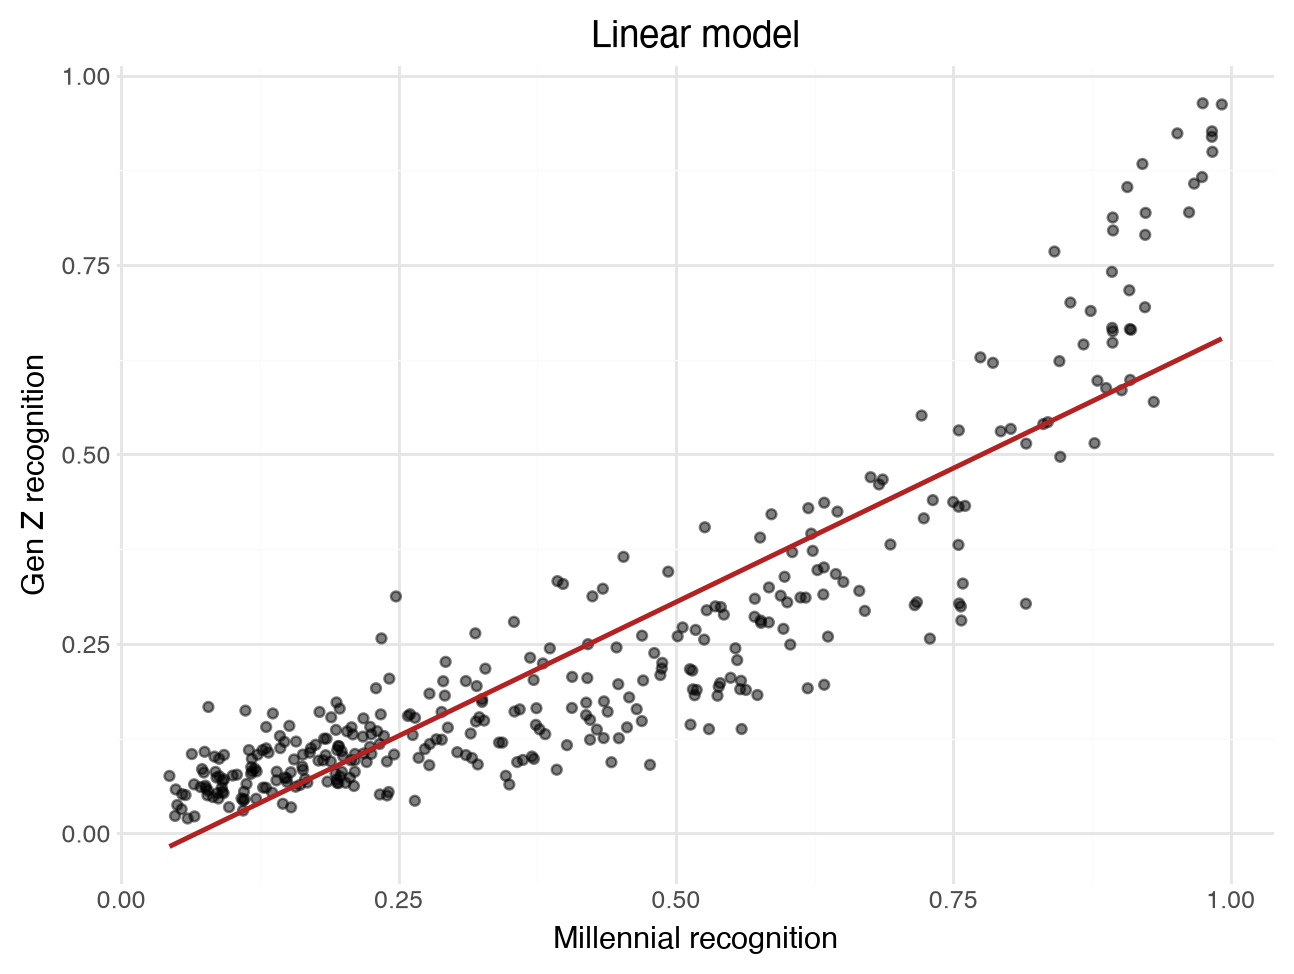

In [33]:
from plotnine import ggplot, aes, geom_point, geom_line, labs, theme_minimal

grid = pd.DataFrame({
    "mean_millennial_recognition": np.linspace(
        songs["mean_millennial_recognition"].min(),
        songs["mean_millennial_recognition"].max(),
        100)
})
grid["pred_linear"] = model_linear.predict(grid[["mean_millennial_recognition"]])

(ggplot(songs, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
 + geom_point(alpha=0.5)
 + geom_line(aes(y="pred_linear"), data=grid, color="firebrick", size=1)
 + labs(x="Millennial recognition", y="Gen Z recognition", title="Linear model")
 + theme_minimal())

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

The variable is right-skewed and only takes positive values, so a straight-line fit on the raw proportions can predict below 0 for low-recognition songs, which can’t happen for a proportion. Taking a log pulls in the long tail, makes the relationship more linear, and keeps predictions positive once we transform back.

In [34]:
songs["log_gen_z_recognition"] = np.log(songs["mean_gen_z_recognition"])

X = songs[["mean_millennial_recognition"]]
y_log = songs["log_gen_z_recognition"]

model_log = LinearRegression()
model_log.fit(X, y_log)

print("intercept:", round(model_log.intercept_, 4))
print("coef:     ", model_log.coef_.round(4))
print("R²:       ", round(model_log.score(X, y_log), 3))

intercept: -2.9083
coef:      [2.7992]
R²:        0.823


4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

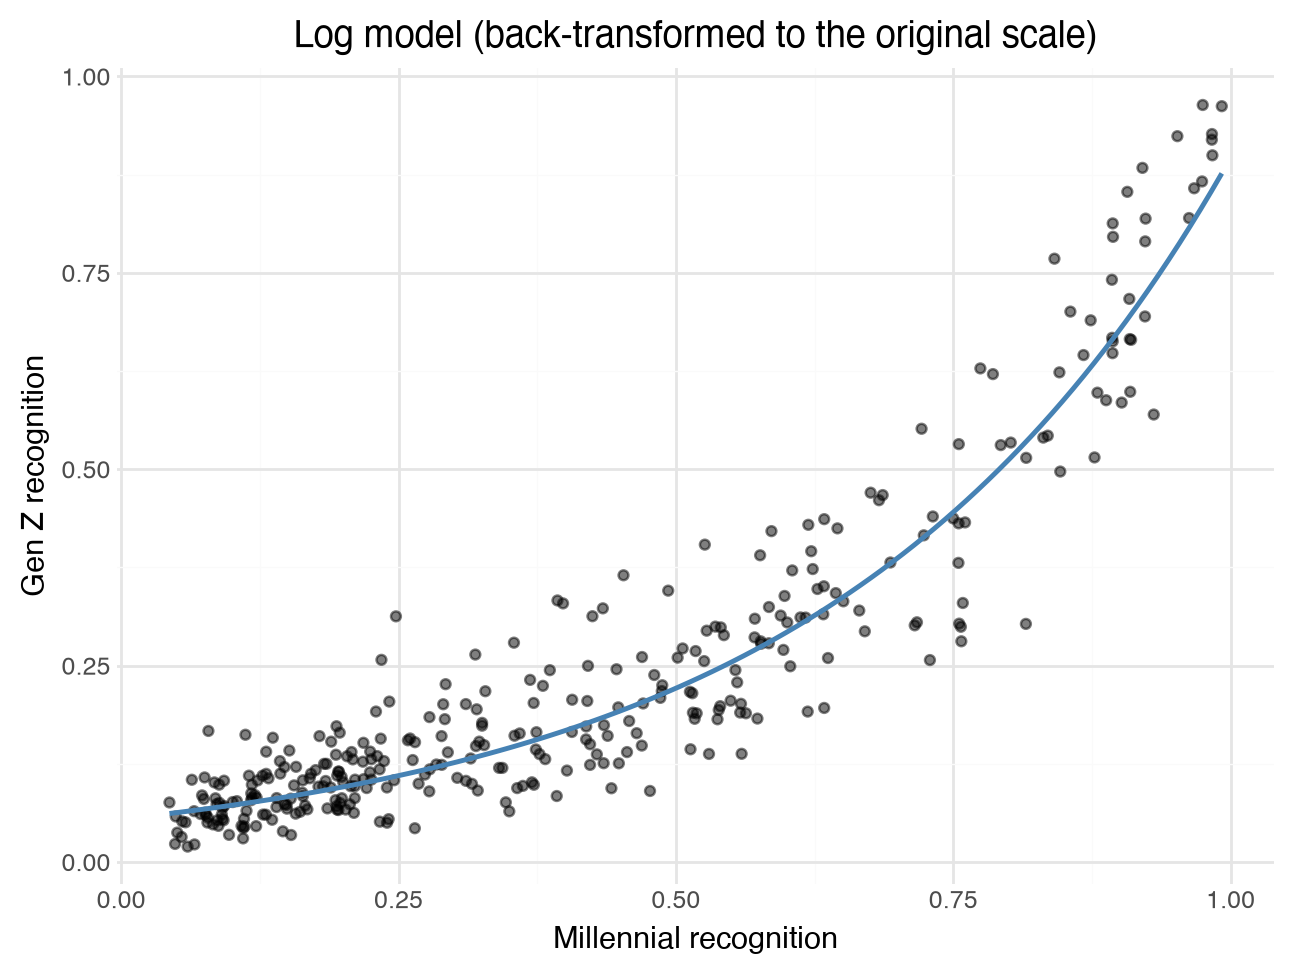

In [35]:
grid["pred_log"] = model_log.predict(grid[["mean_millennial_recognition"]])
grid["pred_log_backtransformed"] = np.exp(grid["pred_log"])

(ggplot(songs, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
 + geom_point(alpha=0.5)
 + geom_line(aes(y="pred_log_backtransformed"), data=grid, color="steelblue", size=1)
 + labs(x="Millennial recognition", y="Gen Z recognition", title="Log model (back-transformed to the original scale)")
 + theme_minimal())

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

In [36]:
songs["millennial_sq"] = songs["mean_millennial_recognition"] ** 2

X_sq = songs[["mean_millennial_recognition", "millennial_sq"]]
y = songs["mean_gen_z_recognition"]

square_model = LinearRegression()
square_model.fit(X_sq, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.27, 1.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['mean_millennial_recognition','millennial_sq']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1085
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [37]:
square_model.coef_, square_model.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257645))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

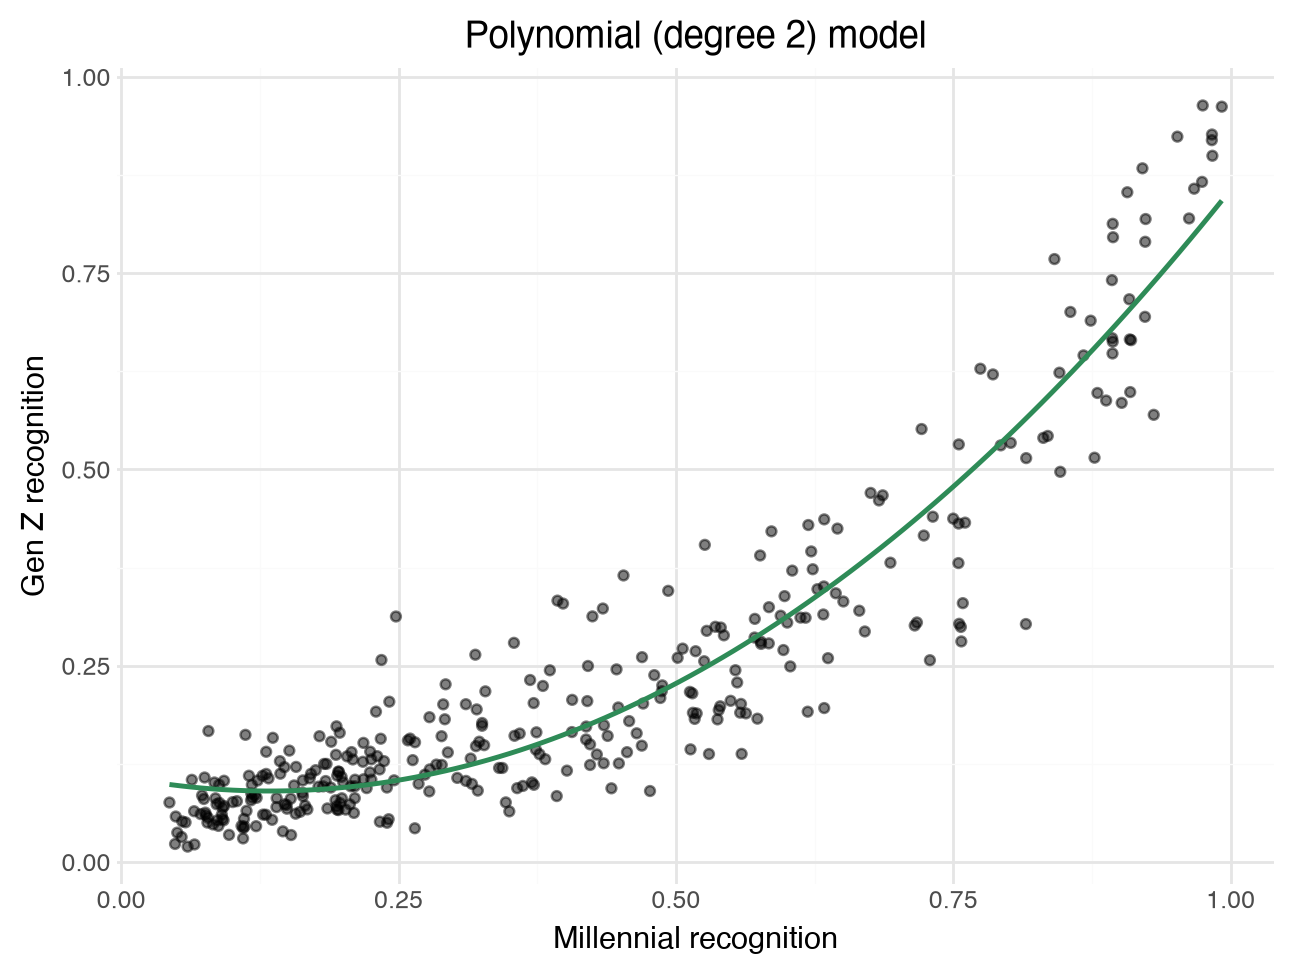

In [38]:
grid["millennial_sq"] = grid["mean_millennial_recognition"] ** 2
grid["pred_poly"] = square_model.predict(grid[["mean_millennial_recognition", "millennial_sq"]])

(ggplot(songs, aes(x="mean_millennial_recognition", y="mean_gen_z_recognition"))
 + geom_point(alpha=0.5)
 + geom_line(aes(y="pred_poly"), data=grid, color="seagreen", size=1)
 + labs(x="Millennial recognition", y="Gen Z recognition", title="Polynomial (degree 2) model")
 + theme_minimal())

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

In [39]:
favorite = songs[songs["artist_song"] == "Backstreet Boys, The|||Everybody"]
favorite

,artist_song,mean_millennial_recognition,mean_gen_z_recognition,log_gen_z_recognition,millennial_sq
21,"Backstreet Boys, The|||Everybody",0.966933,0.857472,-0.153767,0.934959


In [40]:
mill_value = favorite["mean_millennial_recognition"].values[0]
actual = favorite["mean_gen_z_recognition"].values[0]

new_song = pd.DataFrame({"mean_millennial_recognition": [mill_value]})
new_song["millennial_sq"] = new_song["mean_millennial_recognition"] ** 2

pred_linear = model_linear.predict(new_song[["mean_millennial_recognition"]])[0]
pred_log = np.exp(model_log.predict(new_song[["mean_millennial_recognition"]])[0])
pred_poly = square_model.predict(new_song[["mean_millennial_recognition", "millennial_sq"]])[0]

print(f"Actual Gen Z recognition:   {actual:.3f}")
print(f"Linear model prediction:    {pred_linear:.3f}")
print(f"Log model prediction:       {pred_log:.3f}")
print(f"Polynomial model prediction:{pred_poly:.3f}")

Actual Gen Z recognition:   0.857
Linear model prediction:    0.635
Log model prediction:       0.817
Polynomial model prediction:0.799


For the song "Everybody" by Backstreet Boys, actual Gen Z recognition is 0.857. The log model comes closest (0.817), then the polynomial model (0.799). 

8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

In [41]:
teen_spirit = pd.DataFrame({"mean_millennial_recognition": [0.7]})
teen_spirit["millennial_sq"] = teen_spirit["mean_millennial_recognition"] ** 2

pred_linear_ts = model_linear.predict(teen_spirit[["mean_millennial_recognition"]])[0]
pred_log_ts = np.exp(model_log.predict(teen_spirit[["mean_millennial_recognition"]])[0])
pred_poly_ts = square_model.predict(teen_spirit[["mean_millennial_recognition", "millennial_sq"]])[0]

print(f"Linear model prediction:    {pred_linear_ts:.3f}")
print(f"Log model prediction:       {pred_log_ts:.3f}")
print(f"Polynomial model prediction:{pred_poly_ts:.3f}")

Linear model prediction:    0.447
Log model prediction:       0.387
Polynomial model prediction:0.418


Since there's no actual Gen Z recognition value to check these against, we can't concretely state which model gives the best prediction. Given how popular this song is even in younger generations,  a model that predicts toward the higher end might be closer. Based on this, I would guess that the linear model gives the best prediction (0.447). 

## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [42]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

In [ ]:
smoke_dummies = pd.get_dummies(df_fev["Smoking status"], drop_first=True)  
df_fev = pd.concat([df_fev, smoke_dummies], axis=1)
df_fev["smoker"] = df_fev["smoker"].astype(int)

X_smoke = df_fev[["smoker"]]
y_fev = df_fev["FEV"]

model_smoke = LinearRegression()
model_smoke.fit(X_smoke, y_fev)

print("intercept:", round(model_smoke.intercept_, 4))
print("coef:     ", model_smoke.coef_.round(4))

intercept: 2.5661
coef:      [0.7107]


2\. What are the predictions from this model? How could we have known that those would be the predictions?

In [44]:
df_fev["pred_smoke_model"] = model_smoke.predict(X_smoke)
print(sorted(df_fev["pred_smoke_model"].unique()))

df_fev.groupby("Smoking status")["FEV"].mean()

[np.float64(2.5661426146010187), np.float64(3.276861538461541)]


Smoking status
non-smoker    2.566143
smoker        3.276862
Name: FEV, dtype: float64

Smoking status is the only predictor, and it can only be 0 (non-smoker) or 1 (smoker). So the model can only make two predictions: 2.566 for every non-smoker and 3.277 for every smoker. 

3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

Smokers have the higher predicted FEV (3.277 vs. 2.566 for non-smokers). This is the opposite of what we'd expect if smoking damages lung function. This is not what common sense predicts.

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

An explanation could be age since everyone in this study is a child or teenager and lungs grow as kids get older and bigger. The smokers are older, and older kids are also taller and bigger bodies/lungs, so maybe smokers have higher FEV because they are older and bigger.

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

In [45]:
X_age = df_fev[["smoker", "Age (months)"]]

model_age = LinearRegression()
model_age.fit(X_age, y_fev)

print(pd.Series(model_age.coef_, index=X_age.columns).round(6))
print("intercept:", round(model_age.intercept_, 4))
print("R²:", round(model_age.score(X_age, y_fev), 4))

smoker         -0.217178
Age (months)    0.019212
dtype: float64
intercept: 0.3681
R²: 0.5759


6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

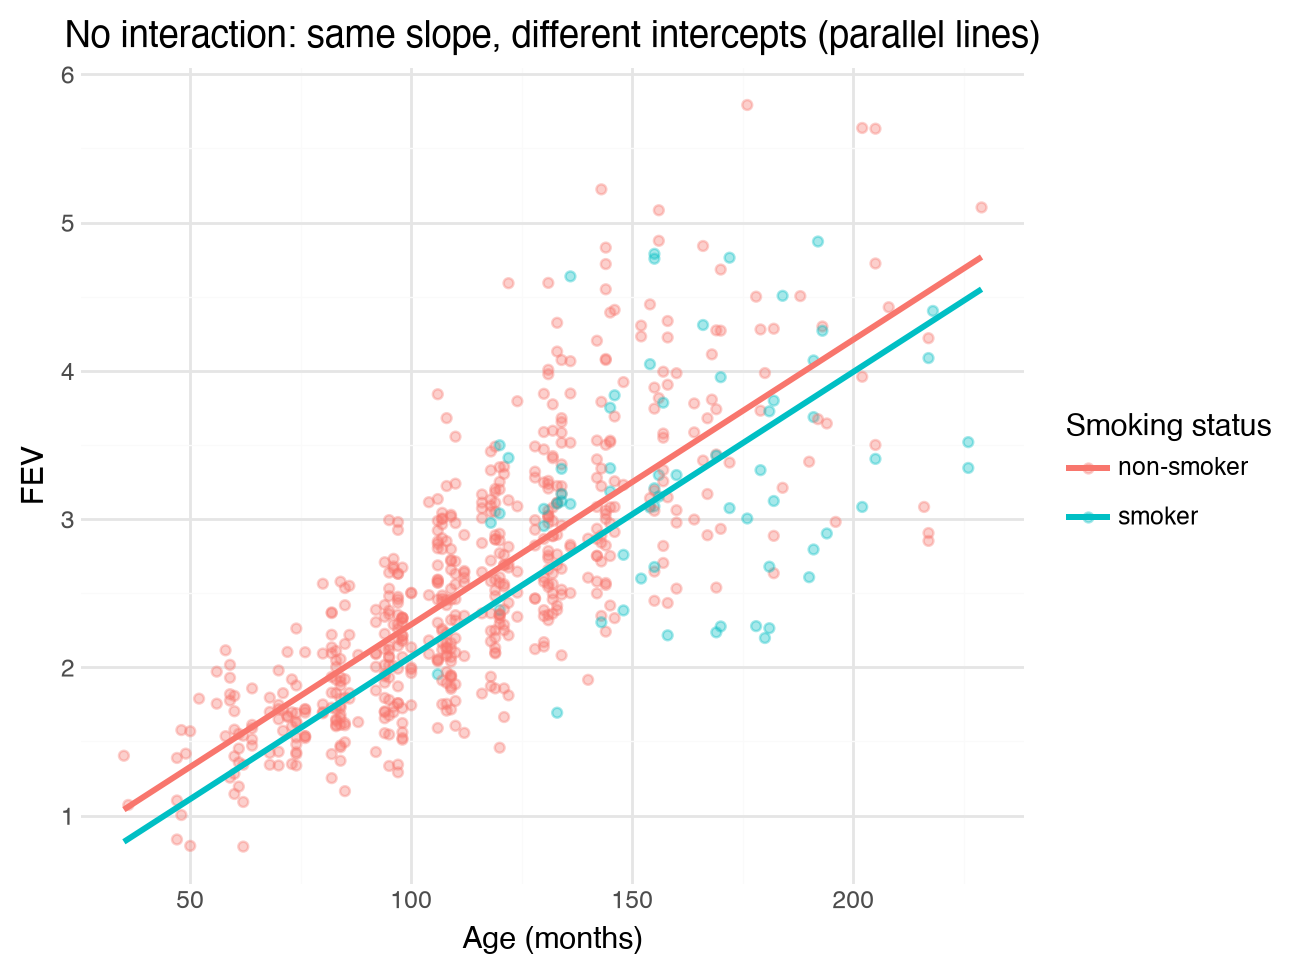

In [46]:
age_grid = pd.DataFrame({
    "Age (months)": np.tile(np.linspace(df_fev["Age (months)"].min(), df_fev["Age (months)"].max(), 50), 2),
    "smoker": np.repeat([0, 1], 50),
})
age_grid["pred_fev"] = model_age.predict(age_grid[["smoker", "Age (months)"]])
age_grid["Smoking status"] = age_grid["smoker"].map({0: "non-smoker", 1: "smoker"})

from plotnine import scale_color_manual

(ggplot(df_fev, aes(x="Age (months)", y="FEV", color="Smoking status"))
 + geom_point(alpha=0.35)
 + geom_line(data=age_grid, mapping=aes(x="Age (months)", y="pred_fev", color="Smoking status"), size=1.2)
 + labs(title="No interaction: same slope, different intercepts (parallel lines)")
 + theme_minimal())

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

In [48]:
df_fev["age_x_smoker"] = df_fev["Age (months)"] * df_fev["smoker"]

X_int = df_fev[["smoker", "Age (months)", "age_x_smoker"]]

model_int = LinearRegression()
model_int.fit(X_int, y_fev)

print(pd.Series(model_int.coef_, index=X_int.columns).round(6))
print("intercept:", round(model_int.intercept_, 4))
print("R²:", round(model_int.score(X_int, y_fev), 4))

smoker          1.870057
Age (months)    0.020162
age_x_smoker   -0.013110
dtype: float64
intercept: 0.2595
R²: 0.592


8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

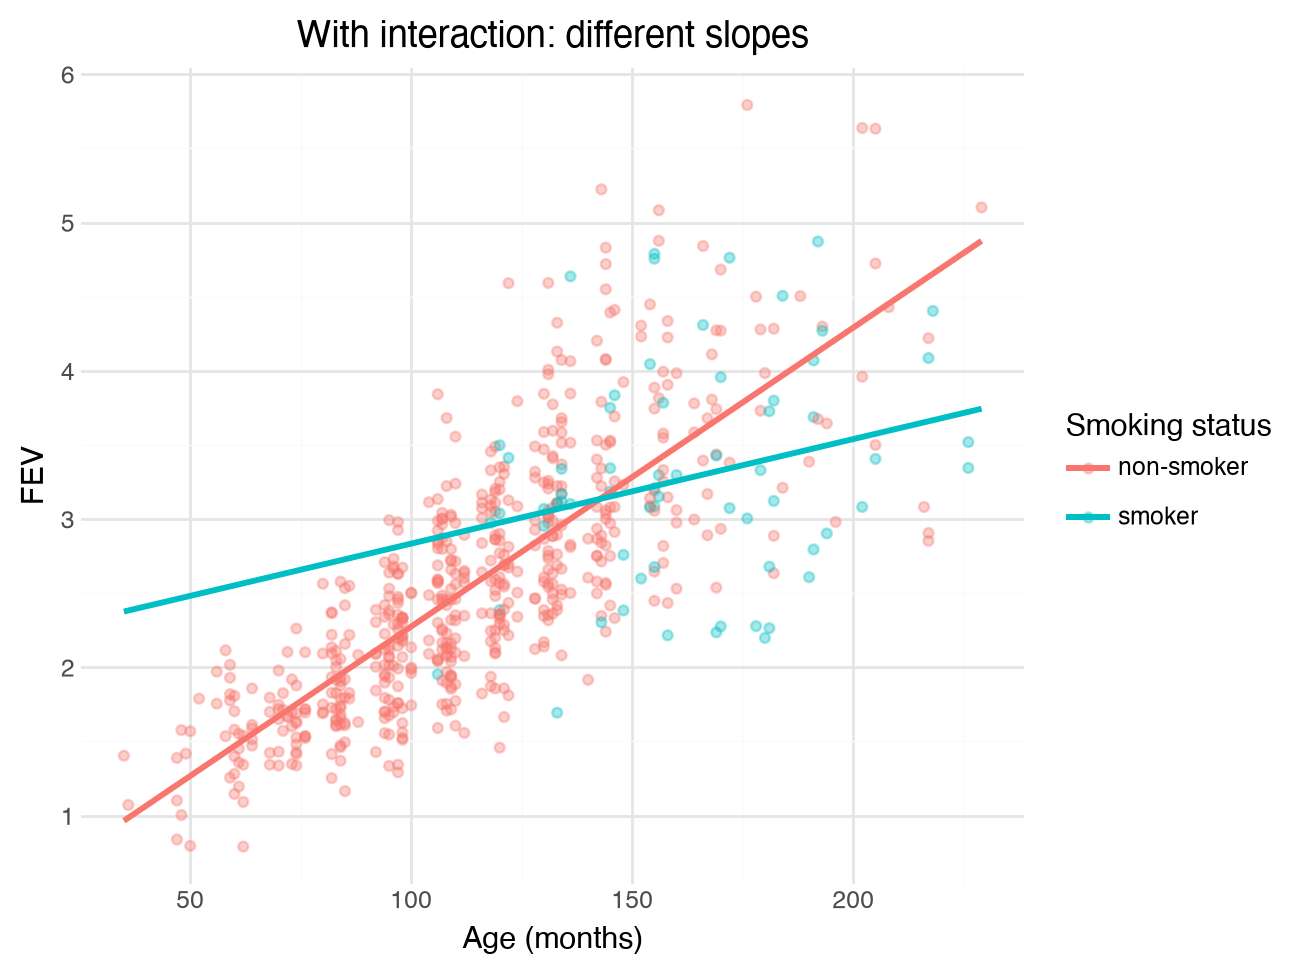

In [49]:
age_grid["age_x_smoker"] = age_grid["Age (months)"] * age_grid["smoker"]
age_grid["pred_fev_int"] = model_int.predict(age_grid[["smoker", "Age (months)", "age_x_smoker"]])

(ggplot(df_fev, aes(x="Age (months)", y="FEV", color="Smoking status"))
 + geom_point(alpha=0.35)
 + geom_line(data=age_grid, mapping=aes(x="Age (months)", y="pred_fev_int", color="Smoking status"), size=1.2)
 + labs(title="With interaction: different slopes")
 + theme_minimal())

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

In [50]:
for name, Xcols, m in [
    ("smoking only", ["smoker"], model_smoke),
    ("smoking + age", ["smoker", "Age (months)"], model_age),
    ("smoking + age + interaction", ["smoker", "Age (months)", "age_x_smoker"], model_int),
]:
    r2 = m.score(df_fev[Xcols], y_fev)
    print(f"{name:30s} R² = {r2:.4f}")

smoking only                   R² = 0.0602
smoking + age                  R² = 0.5759
smoking + age + interaction    R² = 0.5920


The smoking + age + interaction model is best since it has the highest R² (0.592). The interaction term lets smokers and non-smokers have different slopes, not just different starting points, matching the scatterplot. I could investigate further by partitioning the data into a training set and a test set, fit the model on the training set, and check its predictions against the test set, to make sure the extra complexity isn’t just overfitting. 